# Apple Stock

### Introduction:

We are going to use Apple's stock price.


### Step 1. Import the necessary libraries

In [16]:
import pandas as pd
import numpy as np


### Step 2. Import the dataset from this [address](https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/09_Time_Series/Apple_Stock/appl_1980_2014.csv)

In [17]:
address = "https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/09_Time_Series/Apple_Stock/appl_1980_2014.csv"



### Step 3. Assign it to a variable apple and apply a head()

In [18]:
apple = pd.read_csv(address)
apple

,Date,Open,High,Low,Close,Volume,Adj Close
0,2014-07-08,96.27,96.80,93.92,95.35,65130000,95.35
1,2014-07-07,94.14,95.99,94.10,95.97,56305400,95.97
2,2014-07-03,93.67,94.10,93.20,94.03,22891800,94.03
3,2014-07-02,93.87,94.06,93.09,93.48,28420900,93.48
4,2014-07-01,93.52,94.07,93.13,93.52,38170200,93.52
...,...,...,...,...,...,...,...
8460,1980-12-18,26.63,26.75,26.63,26.63,18362400,0.41
8461,1980-12-17,25.87,26.00,25.87,25.87,21610400,0.40
8462,1980-12-16,25.37,25.37,25.25,25.25,26432000,0.39
8463,1980-12-15,27.38,27.38,27.25,27.25,43971200,0.42


### Step 4.  Check out the type of the columns

In [19]:
apple.dtypes

Date          object
Open         float64
High         float64
Low          float64
Close        float64
Volume         int64
Adj Close    float64
dtype: object

In [20]:
apple.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8465 entries, 0 to 8464
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       8465 non-null   object 
 1   Open       8465 non-null   float64
 2   High       8465 non-null   float64
 3   Low        8465 non-null   float64
 4   Close      8465 non-null   float64
 5   Volume     8465 non-null   int64  
 6   Adj Close  8465 non-null   float64
dtypes: float64(5), int64(1), object(1)
memory usage: 463.1+ KB


### Step 5. Transform the Date column as a datetime type and check the info()

In [21]:
apple['Date'] = pd.to_datetime(apple['Date'])

apple.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8465 entries, 0 to 8464
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       8465 non-null   datetime64[ns]
 1   Open       8465 non-null   float64       
 2   High       8465 non-null   float64       
 3   Low        8465 non-null   float64       
 4   Close      8465 non-null   float64       
 5   Volume     8465 non-null   int64         
 6   Adj Close  8465 non-null   float64       
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 463.1 KB


### Step 6.  Set the date as the index

In [22]:
apple.set_index('Date')


,Open,High,Low,Close,Volume,Adj Close
Date,,,,,,
2014-07-08,96.27,96.80,93.92,95.35,65130000,95.35
2014-07-07,94.14,95.99,94.10,95.97,56305400,95.97
2014-07-03,93.67,94.10,93.20,94.03,22891800,94.03
2014-07-02,93.87,94.06,93.09,93.48,28420900,93.48
2014-07-01,93.52,94.07,93.13,93.52,38170200,93.52
...,...,...,...,...,...,...
1980-12-18,26.63,26.75,26.63,26.63,18362400,0.41
1980-12-17,25.87,26.00,25.87,25.87,21610400,0.40
1980-12-16,25.37,25.37,25.25,25.25,26432000,0.39


### Step 7.  Is there any duplicate dates?

In [23]:
apple.index.has_duplicates

False

In [24]:
apple['Date'].duplicated().any()


np.False_

In [24]:
apple.index[apple.index.duplicated()]

Index([], dtype='int64')

### Step 8.  Ops...it seems the index is from the most recent date. Make the first entry the oldest date.

In [29]:
apple = apple.sort_index(ascending=False)
apple.head()


,Date,Open,High,Low,Close,Volume,Adj Close
8464,1980-12-12,28.75,28.87,28.75,28.75,117258400,0.45
8463,1980-12-15,27.38,27.38,27.25,27.25,43971200,0.42
8462,1980-12-16,25.37,25.37,25.25,25.25,26432000,0.39
8461,1980-12-17,25.87,26.00,25.87,25.87,21610400,0.40
8460,1980-12-18,26.63,26.75,26.63,26.63,18362400,0.41


### Step 9. Get the last business day of each month

In [46]:
apple.groupby(apple['Date'].dt.to_period('M'))['Date'].max().dt.day

Date
1980-12    31
1981-01    30
1981-02    27
1981-03    31
1981-04    30
           ..
2014-03    31
2014-04    30
2014-05    30
2014-06    30
2014-07     8
Freq: M, Name: Date, Length: 404, dtype: int32

### Step 10.  What is the difference in days between the first day and the oldest

In [ ]:
apple.groupby(apple['Date'].dt.to_period('M'))['Date'].agg(lambda x: (x.max() - x.min()).days)

'''apple['Date'].dt.to_period('M'): agrupa las fechas por mes y año.
groupby(...)['Date']: toma la columna Date dentro de cada grupo mensual.
agg(...): aplica un cálculo a las fechas de cada mes.
x.max() - x.min(): resta la fecha más antigua de la más reciente.
.days: devuelve la diferencia como número entero de días.'''

Date
1980-12    19
1981-01    28
1981-02    25
1981-03    29
1981-04    29
           ..
2014-03    28
2014-04    29
2014-05    29
2014-06    28
2014-07     7
Freq: M, Name: Date, Length: 404, dtype: int64

### Step 11.  How many months in the data we have?

In [48]:
apple['Date'].dt.to_period('M').nunique()

404

### Step 12. Plot the 'Adj Close' value. Set the size of the figure to 13.5 x 9 inches

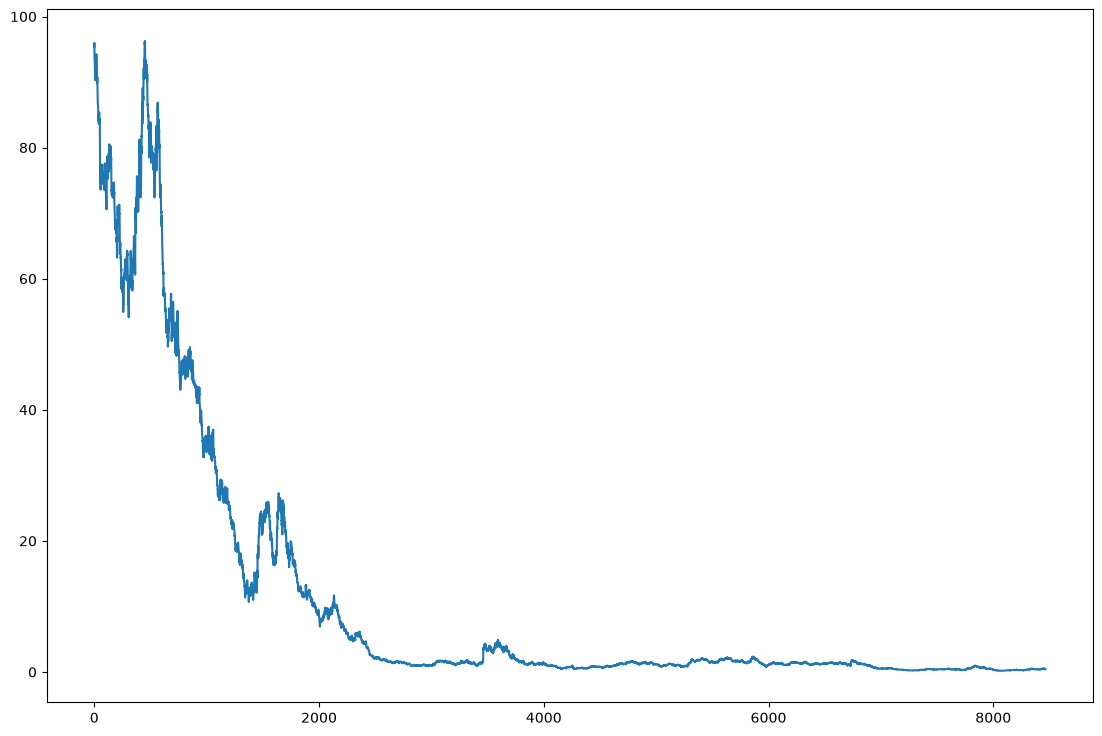

In [50]:
import matplotlib.pyplot as plt

apple['Adj Close'].plot(figsize=(13.5, 9))
plt.show()